# MessMind — 01 Exploratory Data Analysis

**Dataset:** `data/raw/messmind_training_data.csv` — **SYNTHETIC** data produced by `src/generate_data.py`
(seed 42). Every pattern found here was put there by the simulator; it shows what the data *contains*,
not how a real mess behaves.

**Goal:** understand the data, find quality problems and leakage risks, and decide what Phase 4
(preprocessing / feature engineering) must do. **No preprocessing or model training happens here, and
the CSV is only read, never written.**

**Prediction problem (reminder):** one row = one dish at one meal. Target = `actual_dish_consumers`.
`interested_taps` is an *input* recorded before the meal — it is not the same thing as consumption.

Sections:
1. Setup & loading · 2. Overview · 3. Data quality · 4. Categorical distributions ·
5. Numerical distributions & outliers · 6. Target analysis · 7. Taps vs actual consumption ·
8. Other relationships · 9. Time trends · 10. Correlations · 11. New dishes & missing history ·
12. Leakage investigation · 13. Summary

## 1. Setup & loading

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Paths are resolved relative to the ml/ project folder, whether the notebook is run
# from ml/notebooks/ (normal) or from ml/ itself.
ML_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ML_ROOT / "data" / "raw" / "messmind_training_data.csv"
DICT_PATH = ML_ROOT / "docs" / "data_dictionary.md"
FIG_DIR = ML_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "actual_dish_consumers"
MEAL_ORDER = ["breakfast", "lunch", "dinner"]
DAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# Colour-blind-safe categorical colours (fixed order: one colour per meal type, always the same).
MEAL_COLORS = {"breakfast": "#2a78d6", "lunch": "#eb6834", "dinner": "#1baf7a"}
SINGLE = "#2a78d6"   # single-series charts
INK_MUTED = "#6b6a66"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", rc={
    "grid.color": "#e6e5e0", "axes.edgecolor": "#bdbcb6", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": "#3d3c39", "figure.dpi": 100,
})

def save(fig, name):
    """Save a figure to reports/figures/ (generated output, git-ignored)."""
    fig.savefig(FIG_DIR / f"eda_{name}.png", dpi=120, bbox_inches="tight")

print("ML root :", ML_ROOT)
print("Data    :", DATA_PATH.relative_to(ML_ROOT))

ML root : <project-root>\ml
Data    : data\raw\messmind_training_data.csv


In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["date"])   # read-only: this notebook never writes the CSV
df["meal_type"] = pd.Categorical(df["meal_type"], categories=MEAL_ORDER, ordered=True)

print("Shape:", df.shape)
print("data_source values:", df["data_source"].unique().tolist())
assert (df["data_source"] == "synthetic").all(), "expected synthetic data only"

Shape: (1337, 20)
data_source values: ['synthetic']


## 2. Overview — columns, types, memory, first/last rows

In [3]:
df.info(memory_usage="deep")
print(f"\nMemory usage: {df.memory_usage(deep=True).sum() / 1024:.1f} KB")

<class 'pandas.DataFrame'>
RangeIndex: 1337 entries, 0 to 1336
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      1337 non-null   datetime64[us]
 1   meal_type                 1337 non-null   category      
 2   dish_name                 1337 non-null   str           
 3   dish_category             1337 non-null   str           
 4   day_of_week               1337 non-null   int64         
 5   is_weekend                1337 non-null   bool          
 6   is_holiday                1337 non-null   bool          
 7   is_exam_day               1337 non-null   bool          
 8   is_festival               1337 non-null   bool          
 9   temperature               1337 non-null   float64       
 10  rainfall                  1337 non-null   float64       
 11  total_students            1337 non-null   int64         
 12  previous_meal_attendance  1337 

In [4]:
display(df.head())
display(df.tail())

,date,meal_type,dish_name,dish_category,day_of_week,is_weekend,is_holiday,is_exam_day,is_festival,temperature,rainfall,total_students,previous_meal_attendance,historical_dish_demand,historical_dish_rating,interested_taps,total_responses,previous_leftover_kg,actual_dish_consumers,data_source
0,2026-07-01,breakfast,Boiled Eggs,side,2,False,False,False,False,28.7,5.6,1000,795.0,145.6,3.56,78,361,12.3,194,synthetic
1,2026-07-01,breakfast,Bread Omelette,breakfast_item,2,False,False,False,False,28.7,5.6,1000,795.0,260.8,4.17,114,361,13.3,273,synthetic
2,2026-07-01,breakfast,Cornflakes and Milk,breakfast_item,2,False,False,False,False,28.7,5.6,1000,795.0,127.2,3.40,54,361,20.3,152,synthetic
3,2026-07-01,breakfast,Poha,breakfast_item,2,False,False,False,False,28.7,5.6,1000,795.0,244.8,3.46,135,361,2.6,333,synthetic
4,2026-07-01,breakfast,Tea,beverage,2,False,False,False,False,28.7,5.6,1000,795.0,350.2,3.68,187,361,3.4,615,synthetic


,date,meal_type,dish_name,dish_category,day_of_week,is_weekend,is_holiday,is_exam_day,is_festival,temperature,rainfall,total_students,previous_meal_attendance,historical_dish_demand,historical_dish_rating,interested_taps,total_responses,previous_leftover_kg,actual_dish_consumers,data_source
1332,2026-09-28,dinner,Aloo Matar,main_veg,0,False,False,False,False,31.4,0.0,1000,816.0,293.6,3.23,131,424,6.4,320,synthetic
1333,2026-09-28,dinner,Chapati,bread,0,False,False,False,False,31.4,0.0,1000,816.0,647.8,3.67,210,424,13.4,576,synthetic
1334,2026-09-28,dinner,Dal Fry,dal,0,False,False,False,False,31.4,0.0,1000,816.0,472.8,3.62,152,424,17.2,473,synthetic
1335,2026-09-28,dinner,Gulab Jamun,dessert,0,False,False,False,False,31.4,0.0,1000,816.0,533.8,4.46,316,424,12.4,552,synthetic
1336,2026-09-28,dinner,Rice,staple_rice,0,False,False,False,False,31.4,0.0,1000,816.0,569.6,3.64,182,424,43.7,533,synthetic


In [5]:
print("Numerical columns")
display(df.describe().T.round(2))
print("Text / categorical columns")
display(df.describe(include=["object", "string", "category"]).T)
print("Boolean columns (share True)")
display(df.select_dtypes("bool").mean().round(3).to_frame("share_true"))

Numerical columns


,count,mean,min,25%,50%,75%,max,std
date,1337,2026-08-14 08:29:26.342558,2026-07-01 00:00:00,2026-07-23 00:00:00,2026-08-14 00:00:00,2026-09-06 00:00:00,2026-09-28 00:00:00,NaN
day_of_week,1337.0,3.034405,0.0,1.0,3.0,5.0,6.0,1.987313
temperature,1337.0,28.971204,23.2,28.3,29.1,29.9,32.3,1.537593
rainfall,1337.0,6.421167,0.0,0.0,0.0,8.3,63.7,11.823204
total_students,1337.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,0.0
previous_meal_attendance,1337.0,687.805535,303.0,583.0,726.0,797.0,956.0,140.073354
historical_dish_demand,1336.0,420.435853,117.6,263.85,435.65,571.05,777.0,176.597911
historical_dish_rating,1336.0,3.749476,2.37,3.52,3.73,3.96,5.0,0.404279
interested_taps,1337.0,162.416604,23.0,105.0,160.0,214.0,422.0,71.673562
total_responses,1337.0,401.196709,167.0,357.0,407.0,450.0,575.0,65.040874


Text / categorical columns


,count,unique,top,freq
meal_type,1337,3,dinner,448
dish_name,1337,38,Chapati,180
dish_category,1337,10,breakfast_item,239
data_source,1337,1,synthetic,1337


Boolean columns (share True)


,share_true
is_weekend,0.285
is_holiday,0.043
is_exam_day,0.086
is_festival,0.033


**Interpretation.** 1,337 rows × 20 columns covering 90 days (2026-07-01 → 2026-09-28), about 357 KB in memory, so size is not a concern. Types are as documented: counts are integers, history and weather columns are floats, four calendar flags are booleans, and `dish_name`, `dish_category` and `meal_type` are text. `total_students` has a standard deviation of 0: it is **1000 on every row**, so in this dataset it carries no information.

## 3. Data quality — missing values, duplicates, invalid values

In [6]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct"] = (missing["n_missing"] / len(df) * 100).round(2)
print("Columns with missing values:")
display(missing[missing["n_missing"] > 0])
print("Rows containing any missing value:")
display(df[df.isna().any(axis=1)])

Columns with missing values:


,n_missing,pct
historical_dish_demand,1,0.07
historical_dish_rating,1,0.07
previous_leftover_kg,1,0.07


Rows containing any missing value:


,date,meal_type,dish_name,dish_category,day_of_week,is_weekend,is_holiday,is_exam_day,is_festival,temperature,rainfall,total_students,previous_meal_attendance,historical_dish_demand,historical_dish_rating,interested_taps,total_responses,previous_leftover_kg,actual_dish_consumers,data_source
74,2026-07-05,dinner,Aloo Matar,main_veg,6,True,False,False,False,28.4,19.9,1000,747.0,NaN,NaN,124,339,NaN,299,synthetic


In [7]:
print("Full-row duplicates           :", df.duplicated().sum())
print("Key duplicates (date,meal,dish):", df.duplicated(["date", "meal_type", "dish_name"]).sum())

Full-row duplicates           : 0
Key duplicates (date,meal,dish): 0


In [8]:
meal_keys = ["date", "meal_type"]
per_meal = df.groupby(meal_keys, observed=True)
per_day = df.groupby("date")

checks = {
    "actual < 0":                               (df[TARGET] < 0).sum(),
    "actual > total_students":                  (df[TARGET] > df["total_students"]).sum(),
    "interested_taps < 0":                      (df["interested_taps"] < 0).sum(),
    "interested_taps > total_responses":        (df["interested_taps"] > df["total_responses"]).sum(),
    "total_responses > total_students":         (df["total_responses"] > df["total_students"]).sum(),
    "historical_dish_rating outside [1,5]":     (~df["historical_dish_rating"].dropna().between(1, 5)).sum(),
    "previous_leftover_kg < 0":                 (df["previous_leftover_kg"] < 0).sum(),
    "rainfall < 0":                             (df["rainfall"] < 0).sum(),
    "temperature outside [0,50] C":             (~df["temperature"].between(0, 50)).sum(),
    "meals with <4 or >6 dishes":               (~per_meal.size().between(4, 6)).sum(),
    "total_responses differs within a meal":    (per_meal["total_responses"].nunique() > 1).sum(),
    "previous_meal_attendance differs in meal": (per_meal["previous_meal_attendance"].nunique() > 1).sum(),
    "day_of_week != date weekday":              (df["day_of_week"] != df["date"].dt.day_of_week).sum(),
    "is_weekend != (day_of_week >= 5)":         (df["is_weekend"] != (df["day_of_week"] >= 5)).sum(),
    "calendar/weather differs within a day":    sum((per_day[c].nunique() > 1).sum() for c in
                                                    ["is_holiday", "is_exam_day", "is_festival", "temperature", "rainfall"]),
}
pd.Series(checks, name="n_violations").to_frame()

,n_violations
actual < 0,0
actual > total_students,0
interested_taps < 0,0
interested_taps > total_responses,0
total_responses > total_students,0
"historical_dish_rating outside [1,5]",0
previous_leftover_kg < 0,0
rainfall < 0,0
"temperature outside [0,50] C",0
meals with <4 or >6 dishes,0


**Interpretation.** The data is clean. There are no duplicates (full-row or by date + meal + dish), and **all 15 rule checks report 0 violations**: consumers within [0, total_students], taps ≤ responses, consistent calendar and weather within a day, and 4–6 dishes per meal. Only **one row has missing values**, and it is missing all three history columns together (Aloo Matar, dinner, 2026-07-05). Section 11 shows why. Nothing was dropped or filled here.

## 4. Unique counts & categorical distributions

In [9]:
display(df.nunique().to_frame("n_unique"))
print("Rows per meal type:");      display(df["meal_type"].value_counts().sort_index().to_frame())
print("Rows per dish category:");  display(df["dish_category"].value_counts().to_frame())

,n_unique
date,90
meal_type,3
dish_name,38
dish_category,10
day_of_week,7
is_weekend,2
is_holiday,2
is_exam_day,2
is_festival,2
temperature,44


Rows per meal type:


,count
meal_type,
breakfast,445
lunch,444
dinner,448


Rows per dish category:


,count
dish_category,
breakfast_item,239
main_veg,194
bread,180
dal,180
staple_rice,180
beverage,155
side,69
dessert,48
main_nonveg,47


In [10]:
days = df.groupby("date")[["is_weekend", "is_holiday", "is_exam_day", "is_festival"]].first()
print("Number of DAYS with each flag (out of", len(days), "days):")
display(days.sum().to_frame("n_days"))
print("Festival dates:", days.index[days["is_festival"]].strftime("%Y-%m-%d").tolist())
print("Holiday dates :", days.index[days["is_holiday"]].strftime("%Y-%m-%d").tolist())
ex = days.index[days["is_exam_day"]]
print("Exam block    :", ex.min().date(), "->", ex.max().date())

Number of DAYS with each flag (out of 90 days):


,n_days
is_weekend,26
is_holiday,4
is_exam_day,8
is_festival,3


Festival dates: ['2026-07-09', '2026-07-17', '2026-08-13']
Holiday dates : ['2026-07-08', '2026-08-10', '2026-08-27', '2026-09-04']
Exam block    : 2026-09-09 -> 2026-09-16


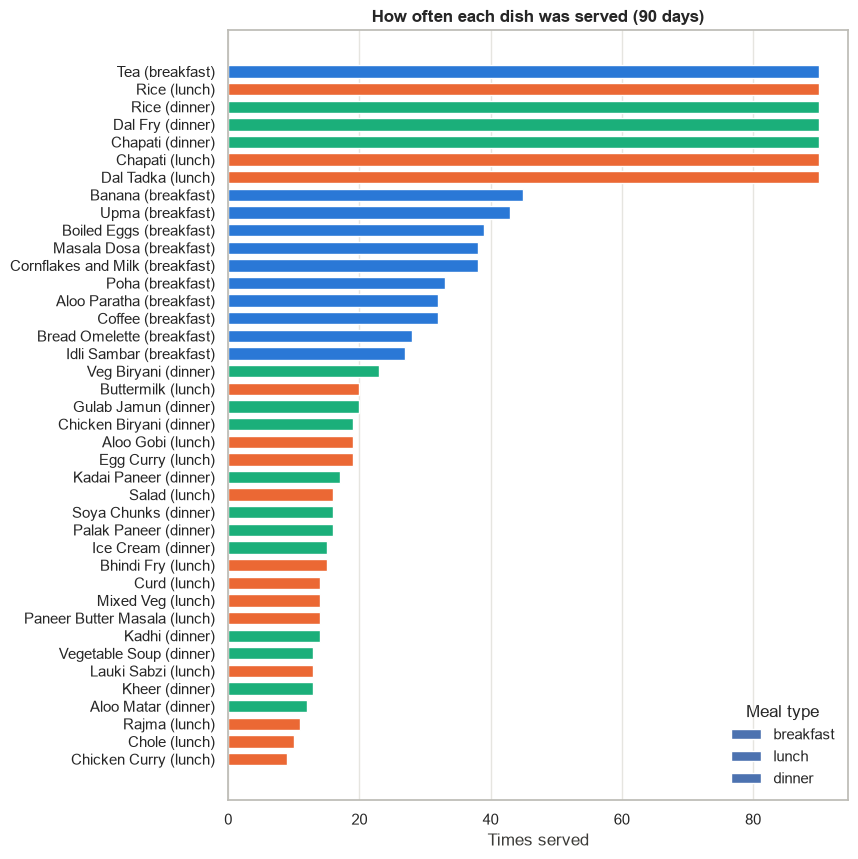

Fewest servings:


,dish_name,meal_type,times_served
11,Chicken Curry,lunch,9
12,Chole,lunch,10
31,Rajma,lunch,11
1,Aloo Matar,dinner,12
24,Kheer,dinner,13


In [11]:
servings = (df.groupby(["dish_name", "meal_type"], observed=True).size()
              .rename("times_served").reset_index().sort_values("times_served"))
servings["label"] = servings["dish_name"] + " (" + servings["meal_type"].astype(str) + ")"

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(servings["label"], servings["times_served"],
        color=servings["meal_type"].map(MEAL_COLORS), height=0.7)
for meal, c in MEAL_COLORS.items():
    ax.barh([], [], color=c, label=meal)
ax.legend(title="Meal type", loc="lower right", frameon=False)
ax.set(title="How often each dish was served (90 days)", xlabel="Times served", ylabel="")
ax.grid(axis="y", visible=False)
save(fig, "dish_servings"); plt.show()
print("Fewest servings:"); display(servings.head(5)[["dish_name", "meal_type", "times_served"]])

**Interpretation.** 38 dish names make 40 dish–meal pairs, because Rice and Chapati are served at both lunch and dinner. Core dishes (Rice, Chapati, Dal, Tea) appear at all 90 meals of their type, while rotating dishes appear only 9–45 times. The rarest are Chicken Curry (lunch, 9 times), Chole (10) and Rajma (11), so the model has few examples of them. `dish_category` has 10 levels, which some dishes share, so it can stand in for dishes with little history. Special days are rare: 4 holidays, 3 festivals and one 8-day exam block (2026-09-09 → 09-16).

## 5. Numerical feature distributions & outliers

total_students unique values: [1000] -> constant, not plotted


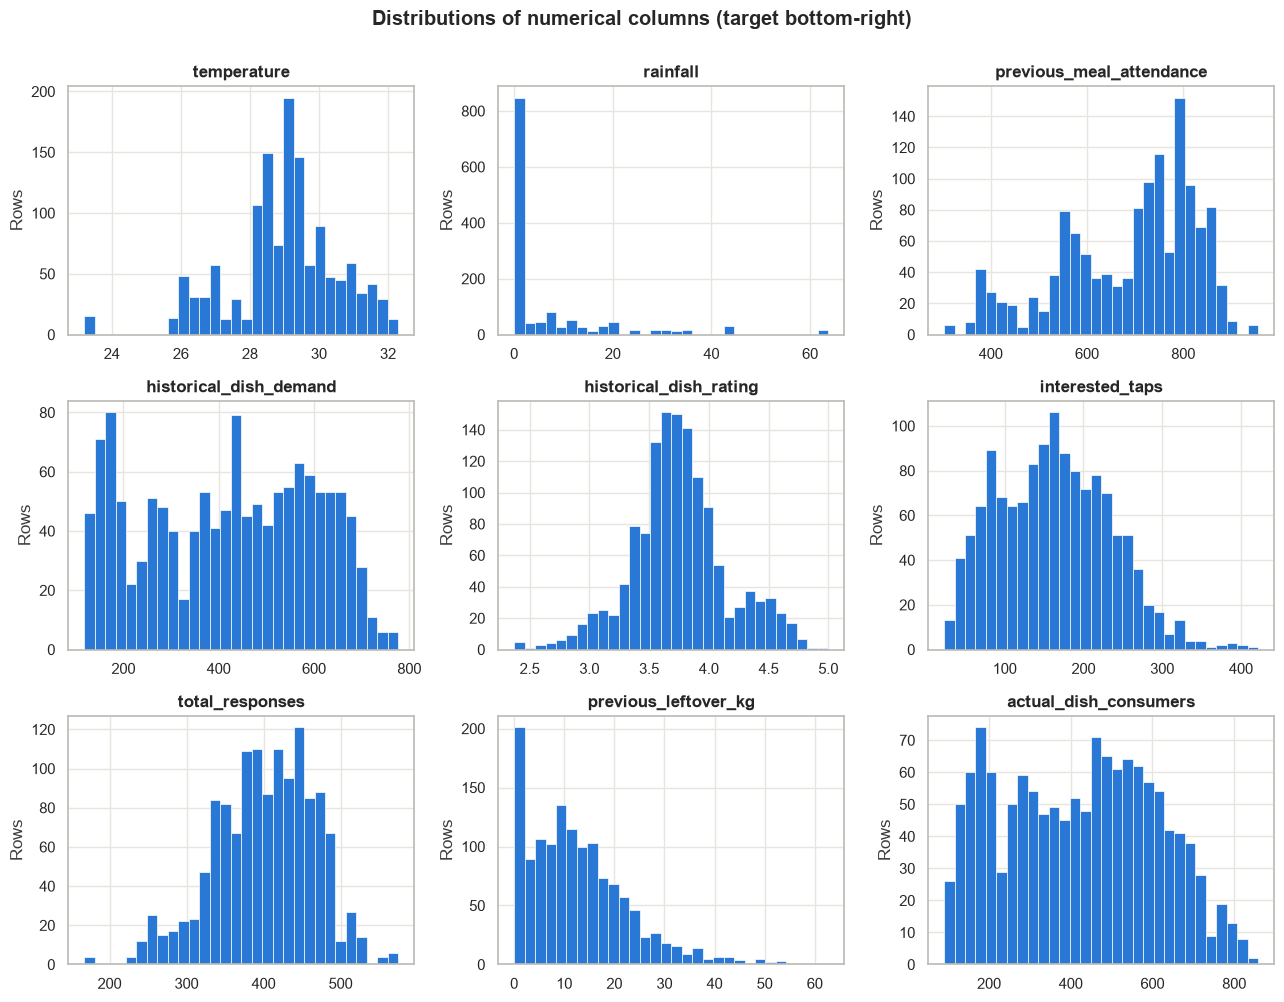

In [12]:
NUM_COLS = ["temperature", "rainfall", "previous_meal_attendance", "historical_dish_demand",
            "historical_dish_rating", "interested_taps", "total_responses", "previous_leftover_kg"]
print("total_students unique values:", df["total_students"].unique(), "-> constant, not plotted")

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, col in zip(axes.flat, NUM_COLS + [TARGET]):
    ax.hist(df[col].dropna(), bins=30, color=SINGLE, edgecolor="white", linewidth=0.5)
    ax.set(title=col, xlabel="", ylabel="Rows")
fig.suptitle("Distributions of numerical columns (target bottom-right)", fontweight="bold", y=1.0)
fig.tight_layout(); save(fig, "numeric_distributions"); plt.show()

In [13]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"low_fence": lo, "high_fence": hi, "n_below": (s < lo).sum(),
                      "n_above": (s > hi).sum(), "min": s.min(), "max": s.max(),
                      "skew": s.skew()})

outliers = pd.DataFrame({c: iqr_outliers(df[c].dropna()) for c in NUM_COLS + [TARGET]}).T
outliers["pct_outliers"] = ((outliers["n_below"] + outliers["n_above"]) / len(df) * 100).round(2)
outliers.round(2)

,low_fence,high_fence,n_below,n_above,min,max,skew,pct_outliers
temperature,25.90,32.30,29.0,0.0,23.20,32.3,-0.64,2.17
rainfall,-12.45,20.75,0.0,138.0,0.00,63.7,2.45,10.32
previous_meal_attendance,262.00,1118.00,0.0,0.0,303.00,956.0,-0.68,0.00
historical_dish_demand,-196.95,1031.85,0.0,0.0,117.60,777.0,-0.10,0.00
historical_dish_rating,2.86,4.62,25.0,34.0,2.37,5.0,0.06,4.41
interested_taps,-58.50,377.50,0.0,7.0,23.00,422.0,0.33,0.52
total_responses,217.50,589.50,4.0,0.0,167.00,575.0,-0.37,0.30
previous_leftover_kg,-14.99,38.31,0.0,31.0,0.00,62.7,1.12,2.32
actual_dish_consumers,-192.00,1024.00,0.0,0.0,90.00,859.0,0.06,0.00


In [14]:
print("Share of dry days (rainfall == 0):",
      round((df.groupby("date")["rainfall"].first() == 0).mean(), 3))
print("Rows with previous_leftover_kg == 0:", (df["previous_leftover_kg"] == 0).sum())
print("Largest rainfall days:")
display(df.groupby("date")["rainfall"].first().nlargest(5).to_frame())

Share of dry days (rainfall == 0): 0.589
Rows with previous_leftover_kg == 0: 153
Largest rainfall days:


,rainfall
date,
2026-08-17,63.7
2026-08-12,44.4
2026-08-15,42.5
2026-09-19,34.0
2026-09-13,33.6


**Interpretation.** Most columns are roughly symmetric. The exceptions are **`rainfall`** and **`previous_leftover_kg`**. `rainfall` is zero-inflated (59% of days are dry; skew 2.45); its 138 IQR outliers are rainy days, not errors. `previous_leftover_kg` is right-skewed, with 153 rows exactly 0 (the previous serving was fully consumed) and 31 high values up to 62.7 kg. `historical_dish_rating` has 59 IQR outliers between 2.37 and 5.0, all inside the valid 1–5 range. **No outlier looks like a data error**, so none should be removed. Tree models (Random Forest, XGBoost) are not affected by skew, so no transformation is required for them.

## 6. Target analysis — `actual_dish_consumers`

In [15]:
t = df[TARGET]
summary = pd.Series({"count": t.count(), "min": t.min(), "max": t.max(), "range": t.max() - t.min(),
                     "mean": t.mean(), "median": t.median(), "std": t.std(), "skew": t.skew(),
                     "share_of_students_max": t.max() / df["total_students"].max()})
display(summary.round(2).to_frame("actual_dish_consumers"))
display(df.groupby("meal_type", observed=True)[TARGET].describe().round(1))

,actual_dish_consumers
count,1337.00
min,90.00
max,859.00
range,769.00
mean,420.41
median,431.00
std,185.90
skew,0.06
share_of_students_max,0.86


,count,mean,std,min,25%,50%,75%,max
meal_type,,,,,,,,
breakfast,445.0,270.2,124.4,90.0,166.0,246.0,361.0,622.0
lunch,444.0,497.5,183.6,107.0,327.8,530.5,647.2,859.0
dinner,448.0,493.2,144.3,138.0,422.0,504.5,594.0,830.0


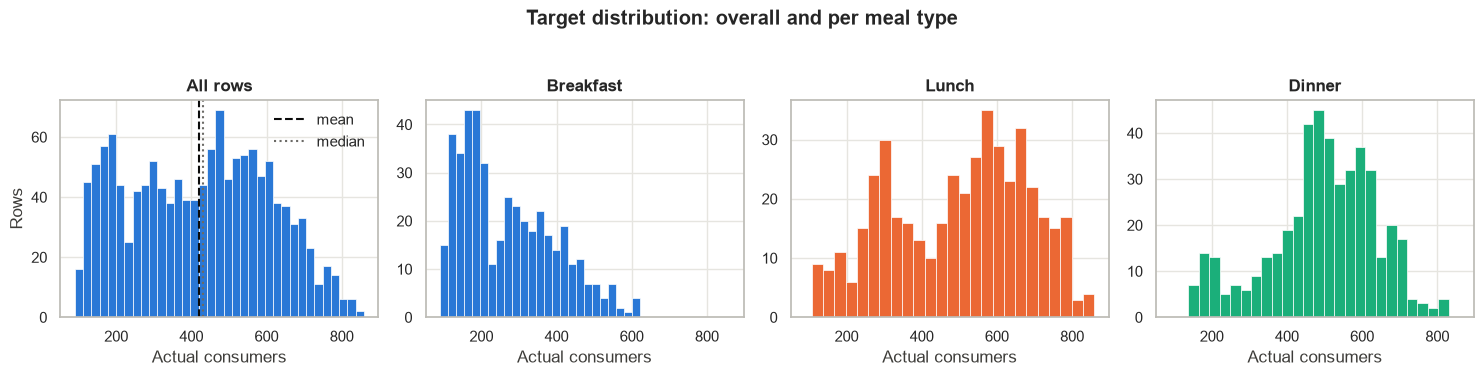

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharex=True)
axes[0].hist(df[TARGET], bins=35, color=SINGLE, edgecolor="white", linewidth=0.5)
axes[0].axvline(df[TARGET].mean(), color="#0b0b0b", lw=1.5, ls="--", label="mean")
axes[0].axvline(df[TARGET].median(), color=INK_MUTED, lw=1.5, ls=":", label="median")
axes[0].legend(frameon=False); axes[0].set(title="All rows", xlabel="Actual consumers", ylabel="Rows")
for ax, meal in zip(axes[1:], MEAL_ORDER):
    ax.hist(df.loc[df["meal_type"] == meal, TARGET], bins=25, color=MEAL_COLORS[meal],
            edgecolor="white", linewidth=0.5)
    ax.set(title=meal.capitalize(), xlabel="Actual consumers")
fig.suptitle("Target distribution: overall and per meal type", fontweight="bold", y=1.04)
fig.tight_layout(); save(fig, "target_distribution"); plt.show()

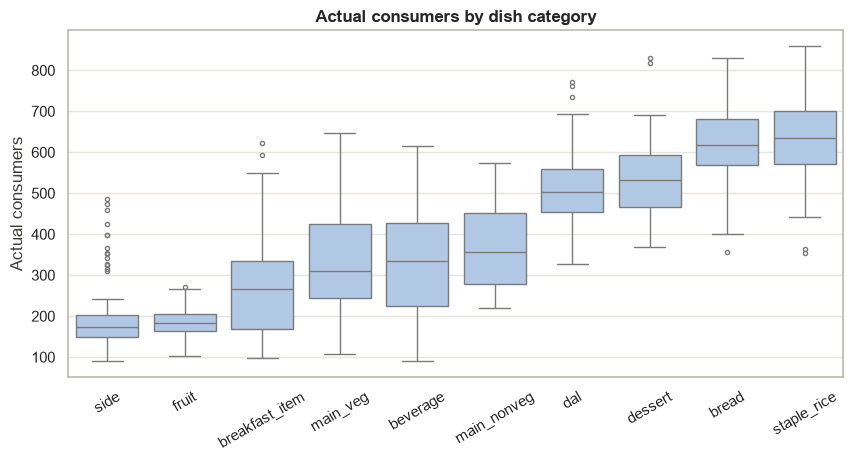

In [17]:
cat_order = df.groupby("dish_category")[TARGET].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x="dish_category", y=TARGET, order=cat_order, color="#a9c8ef",
            linewidth=1, fliersize=3, ax=ax)
ax.set(title="Actual consumers by dish category", xlabel="", ylabel="Actual consumers")
ax.tick_params(axis="x", rotation=30)
save(fig, "target_by_category"); plt.show()

In [18]:
by_dish = (df.groupby(["dish_name", "meal_type"], observed=True)[TARGET]
             .agg(["count", "mean", "std", "min", "max"]).round(1).sort_values("mean"))
print("Lowest-demand dishes:");  display(by_dish.head(6))
print("Highest-demand dishes:"); display(by_dish.tail(6))
print("Per-dish std (typical day-to-day spread of one dish):",
      by_dish["std"].describe()[["min", "50%", "max"]].round(1).to_dict())

Lowest-demand dishes:


,,count,mean,std,min,max
dish_name,meal_type,,,,,
Lauki Sabzi,lunch,13,130.9,14.2,107,160
Cornflakes and Milk,breakfast,38,138.7,26.2,97,212
Boiled Eggs,breakfast,39,151.2,33.9,91,212
Upma,breakfast,43,162.2,32.0,107,254
Coffee,breakfast,32,177.3,46.4,90,281
Salad,lunch,16,183.9,22.6,155,242


Highest-demand dishes:


count   mean    std  min  max
dish_name   meal_type                               
Gulab Jamun dinner        20  554.9   78.8  369  692
Rice        dinner        90  584.8   83.0  354  808
Ice Cream   dinner        15  604.2  117.3  423  830
Chapati     dinner        90  614.1   82.5  400  810
            lunch         90  631.4   92.4  357  830
Rice        lunch         90  681.8   84.2  441  859

Per-dish std (typical day-to-day spread of one dish): {'min': 14.2, '50%': 54.9, 'max': 117.3}


meal_type,breakfast,lunch,dinner
Mon,294.2,522.1,524.7
Tue,294.9,508.9,517.6
Wed,310.1,514.1,490.2
Thu,281.8,505.8,497.3
Fri,289.2,523.3,500.3
Sat,203.7,474.0,469.3
Sun,217.9,439.0,455.7


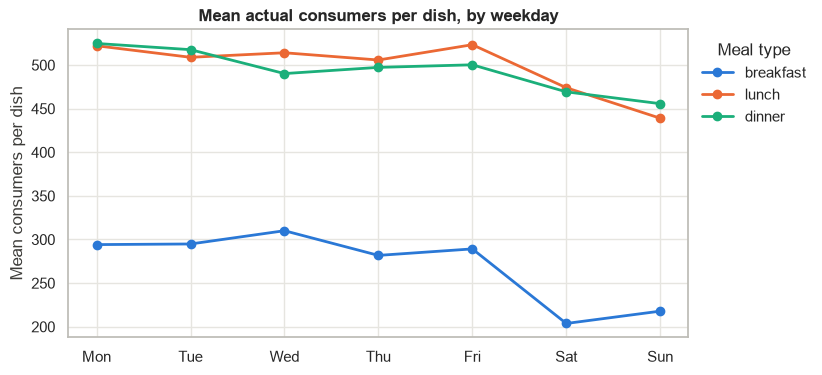

In [19]:
wk = (df.groupby(["day_of_week", "meal_type"], observed=True)[TARGET].mean().unstack())
wk.index = [DAY_NAMES[i] for i in wk.index]
display(wk.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
for meal in MEAL_ORDER:
    ax.plot(wk.index, wk[meal], marker="o", ms=6, lw=2, color=MEAL_COLORS[meal], label=meal)
ax.set(title="Mean actual consumers per dish, by weekday", xlabel="", ylabel="Mean consumers per dish")
ax.legend(title="Meal type", frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
save(fig, "target_by_weekday"); plt.show()

In [20]:
print("total_students unique values:", df["total_students"].unique())

total_students unique values: [1000]


**Interpretation.** `actual_dish_consumers` ranges from 90 to 859 (mean 420, median 431, std 186, skew 0.06), so it is not skewed and needs no log transform. **Meal type is the main driver.** Breakfast dishes average 270 consumers, while lunch and dinner average about 495; the overall distribution is a blend of these. Dish identity matters too: Rice at lunch averages 682 and Lauki Sabzi 131. Within one dish the typical day-to-day spread is a standard deviation of about 55, which is the variation a model has to explain. Weekends are lower, mostly at breakfast (about 204–218 against 282–310 on weekdays). `total_students` is constant, so **its relationship with the target cannot be measured from this data**.

## 7. Interested taps vs actual consumption

Taps are a **pre-meal signal**; actual consumers are the **outcome**. Here we measure how far apart they are
instead of assuming they are equal.

In [21]:
d = df.assign(ratio=df[TARGET] / df["interested_taps"].replace(0, np.nan),
              tap_share=df["interested_taps"] / df["total_responses"],
              consumer_share=df[TARGET] / df["total_students"])
print("corr(interested_taps, actual)              :", round(d["interested_taps"].corr(d[TARGET]), 3))
print("corr(taps / total_responses, actual / total):", round(d["tap_share"].corr(d["consumer_share"]), 3))
print("Rows where actual < taps:", (d[TARGET] < d["interested_taps"]).sum(), "of", len(d))
print("Rows where actual == taps:", (d[TARGET] == d["interested_taps"]).sum())
print("\nactual / taps ratio:")
display(d.groupby("meal_type", observed=True)["ratio"].describe().round(2))
display(d.groupby("dish_category")["ratio"].median().sort_values().round(2).to_frame("median actual/taps"))

corr(interested_taps, actual)              : 0.836
corr(taps / total_responses, actual / total): 0.889
Rows where actual < taps: 0 of 1337
Rows where actual == taps: 0

actual / taps ratio:


,count,mean,std,min,25%,50%,75%,max
meal_type,,,,,,,,
breakfast,445.0,2.63,0.72,1.59,2.14,2.48,2.91,7.08
lunch,444.0,2.68,0.59,1.51,2.21,2.65,3.02,5.20
dinner,448.0,2.64,0.72,1.39,2.15,2.54,3.08,5.59


,median actual/taps
dish_category,
dessert,1.87
main_nonveg,2.00
main_veg,2.12
side,2.28
breakfast_item,2.31
fruit,2.35
beverage,2.78
bread,2.86
dal,2.87


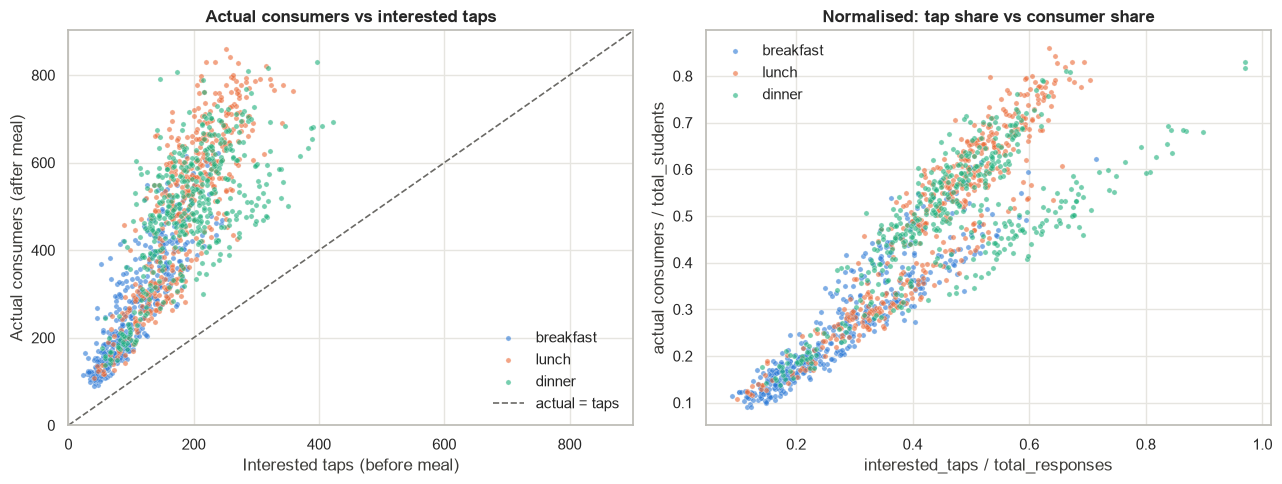

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
for meal in MEAL_ORDER:
    s = d[d["meal_type"] == meal]
    ax.scatter(s["interested_taps"], s[TARGET], s=14, alpha=0.6, color=MEAL_COLORS[meal],
               edgecolor="white", linewidth=0.3, label=meal)
lim = max(d["interested_taps"].max(), d[TARGET].max()) * 1.05
ax.plot([0, lim], [0, lim], color=INK_MUTED, ls="--", lw=1.2, label="actual = taps")
ax.set(xlim=(0, lim), ylim=(0, lim), title="Actual consumers vs interested taps",
       xlabel="Interested taps (before meal)", ylabel="Actual consumers (after meal)")
ax.legend(frameon=False)

ax = axes[1]
for meal in MEAL_ORDER:
    s = d[d["meal_type"] == meal]
    ax.scatter(s["tap_share"], s["consumer_share"], s=14, alpha=0.6, color=MEAL_COLORS[meal],
               edgecolor="white", linewidth=0.3, label=meal)
ax.set(title="Normalised: tap share vs consumer share",
       xlabel="interested_taps / total_responses", ylabel="actual consumers / total_students")
ax.legend(frameon=False)
fig.tight_layout(); save(fig, "taps_vs_actual"); plt.show()

**Interpretation.** **Taps are clearly not consumption.** In every row actual consumers exceed taps (0 of 1,337 rows have actual ≤ taps), on average by about 2.6×, because only about 40% of students respond in the app. The scaling also depends on the dish: staples (rice, dal, bread) have median ratios of about 2.9, while desserts are about 1.9 and non-veg mains about 2.0, since students under-tap staples and over-tap treats. That is why the right-hand plot shows a separate lower band of dinner points. Normalising (taps ÷ responses against consumers ÷ students) raises the correlation from 0.84 to 0.89. So the model needs **both `interested_taps` and `total_responses`, plus dish identity or category**, to turn taps into a consumer estimate.

## 8. Other relationships with the target

### 8.1 Historical demand vs actual demand

corr(historical_dish_demand, actual): 0.912
actual - historical_dish_demand: mean 0.1 | MAE 57.3 | std 76.8


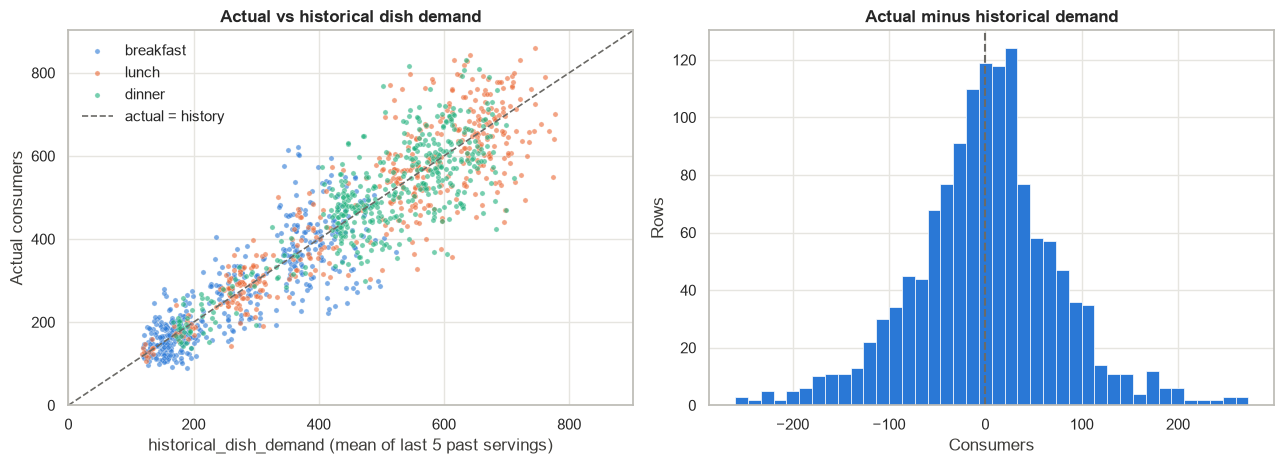

In [23]:
h = df.dropna(subset=["historical_dish_demand"])
resid = h[TARGET] - h["historical_dish_demand"]
print("corr(historical_dish_demand, actual):", round(h["historical_dish_demand"].corr(h[TARGET]), 3))
print("actual - historical_dish_demand: mean", round(resid.mean(), 1), "| MAE", round(resid.abs().mean(), 1),
      "| std", round(resid.std(), 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
for meal in MEAL_ORDER:
    s = h[h["meal_type"] == meal]
    ax.scatter(s["historical_dish_demand"], s[TARGET], s=14, alpha=0.6, color=MEAL_COLORS[meal],
               edgecolor="white", linewidth=0.3, label=meal)
lim = h[[TARGET, "historical_dish_demand"]].max().max() * 1.05
ax.plot([0, lim], [0, lim], color=INK_MUTED, ls="--", lw=1.2, label="actual = history")
ax.set(xlim=(0, lim), ylim=(0, lim), title="Actual vs historical dish demand",
       xlabel="historical_dish_demand (mean of last 5 past servings)", ylabel="Actual consumers")
ax.legend(frameon=False)
axes[1].hist(resid, bins=40, color=SINGLE, edgecolor="white", linewidth=0.5)
axes[1].axvline(0, color=INK_MUTED, ls="--")
axes[1].set(title="Actual minus historical demand", xlabel="Consumers", ylabel="Rows")
fig.tight_layout(); save(fig, "history_vs_actual"); plt.show()

### 8.2 Previous leftovers vs subsequent demand

corr(previous_leftover_kg, actual)                    : 0.162
corr(previous_leftover_kg, actual - historical demand): 0.1


,leftover_kg_mean,actual_mean,demand_vs_history_mean
leftover_bin,,,
Q1 lowest,1.6,437.0,-12.3
Q2,8.2,361.0,-4.6
Q3,14.4,404.5,8.9
Q4 highest,26.7,479.5,8.3


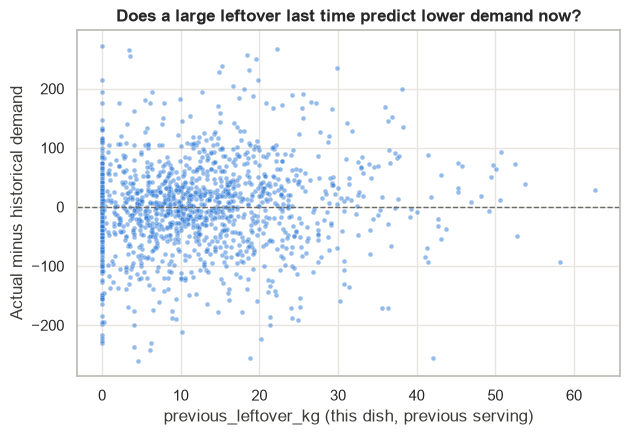

In [24]:
l = df.dropna(subset=["previous_leftover_kg", "historical_dish_demand"]).copy()
l["demand_vs_history"] = l[TARGET] - l["historical_dish_demand"]
print("corr(previous_leftover_kg, actual)                    :", round(l["previous_leftover_kg"].corr(l[TARGET]), 3))
print("corr(previous_leftover_kg, actual - historical demand):", round(l["previous_leftover_kg"].corr(l["demand_vs_history"]), 3))
l["leftover_bin"] = pd.qcut(l["previous_leftover_kg"].rank(method="first"), 4,
                            labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
display(l.groupby("leftover_bin", observed=True)
         .agg(leftover_kg_mean=("previous_leftover_kg", "mean"), actual_mean=(TARGET, "mean"),
              demand_vs_history_mean=("demand_vs_history", "mean")).round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(l["previous_leftover_kg"], l["demand_vs_history"], s=12, alpha=0.5, color=SINGLE,
           edgecolor="white", linewidth=0.3)
ax.axhline(0, color=INK_MUTED, ls="--", lw=1)
ax.set(title="Does a large leftover last time predict lower demand now?",
       xlabel="previous_leftover_kg (this dish, previous serving)",
       ylabel="Actual minus historical demand")
save(fig, "leftover_vs_demand"); plt.show()

### 8.3 Rating, calendar flags and weather

In [25]:
print("corr(historical_dish_rating, actual):", round(df["historical_dish_rating"].corr(df[TARGET]), 3))
print("corr(previous_meal_attendance, actual) overall:", round(df["previous_meal_attendance"].corr(df[TARGET]), 3))
print("  ...within each meal type:", df.groupby("meal_type", observed=True)
      .apply(lambda s: s["previous_meal_attendance"].corr(s[TARGET])).round(3).to_dict())
# Calendar & weather effects measured RELATIVE to each dish's own history, so the menu mix
# (which dishes happened to be served) does not distort the comparison.
e = df.dropna(subset=["historical_dish_demand"]).copy()
e["pct_vs_history"] = (e[TARGET] / e["historical_dish_demand"] - 1) * 100
e["rainy (>5mm)"] = e["rainfall"] > 5
e["hot (>30C)"] = e["temperature"] > 30
rows = []
for flag in ["is_weekend", "is_holiday", "is_exam_day", "is_festival", "rainy (>5mm)", "hot (>30C)"]:
    for meal in MEAL_ORDER:
        s = e[e["meal_type"] == meal]
        rows.append({"flag": flag, "meal_type": meal,
                     "n_rows_true": int(s[flag].sum()),
                     "pct_vs_history_true": s.loc[s[flag], "pct_vs_history"].mean(),
                     "pct_vs_history_false": s.loc[~s[flag], "pct_vs_history"].mean()})
flags = pd.DataFrame(rows)
flags["difference_pts"] = flags["pct_vs_history_true"] - flags["pct_vs_history_false"]
flags.round(1)

corr(historical_dish_rating, actual): 0.317
corr(previous_meal_attendance, actual) overall: -0.094
  ...within each meal type: {'breakfast': 0.103, 'lunch': 0.219, 'dinner': 0.241}


,flag,meal_type,n_rows_true,pct_vs_history_true,pct_vs_history_false,difference_pts
0,is_weekend,breakfast,127,-20.4,9.7,-30.1
1,is_weekend,lunch,129,-9.0,4.5,-13.5
2,is_weekend,dinner,124,-6.8,3.5,-10.3
3,is_holiday,breakfast,16,-17.1,1.8,-18.9
4,is_holiday,lunch,23,-22.8,1.8,-24.6
5,is_holiday,dinner,19,-25.9,1.8,-27.7
6,is_exam_day,breakfast,36,14.0,-0.0,14.0
7,is_exam_day,lunch,39,7.2,-0.1,7.3
8,is_exam_day,dinner,40,8.3,-0.1,8.4
9,is_festival,breakfast,14,12.4,0.7,11.6


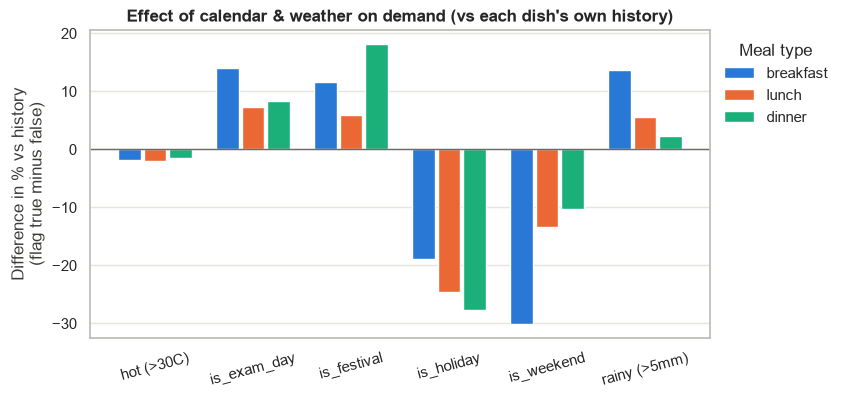

In [26]:
pivot = flags.pivot(index="flag", columns="meal_type", values="difference_pts")[MEAL_ORDER]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(pivot)); w = 0.26
for i, meal in enumerate(MEAL_ORDER):
    ax.bar(x + (i - 1) * w, pivot[meal], width=w - 0.03, color=MEAL_COLORS[meal], label=meal)
ax.axhline(0, color=INK_MUTED, lw=1)
ax.set_xticks(x, pivot.index, rotation=15)
ax.set(title="Effect of calendar & weather on demand (vs each dish's own history)",
       ylabel="Difference in % vs history\n(flag true minus false)")
ax.legend(title="Meal type", frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "flag_effects"); plt.show()

**Interpretation.** **History is the strongest single signal.** `historical_dish_demand` correlates 0.91 with the target; predicting 'same as the last 5 servings' would give an MAE of about 57 consumers with almost no bias (mean residual +0.1). That is a ready-made **baseline** for Phase 5. **Previous leftovers relate only weakly to the next serving's demand** (corr 0.16; 0.10 after removing each dish's history), and the quartile table is not monotonic, so leftovers are not a strong predictor here. `historical_dish_rating` has a moderate correlation (0.32). `previous_meal_attendance` looks useless overall (−0.09) but is positive within each meal type (about 0.10–0.24). The overall figure is distorted because breakfast always follows dinner, which mixes meal types. Measured against each dish's own history, the **calendar effects are large and consistent**. Holidays reduce demand by 19–28 percentage points, weekends by 10–30 (strongest at breakfast), and exam days add 7–14 points. Festivals add up to 18 points at dinner and rain adds up to 14 at breakfast. Hot days show almost no effect (about −2). These patterns match what the simulator was built to do.

## 9. Demand trends over time

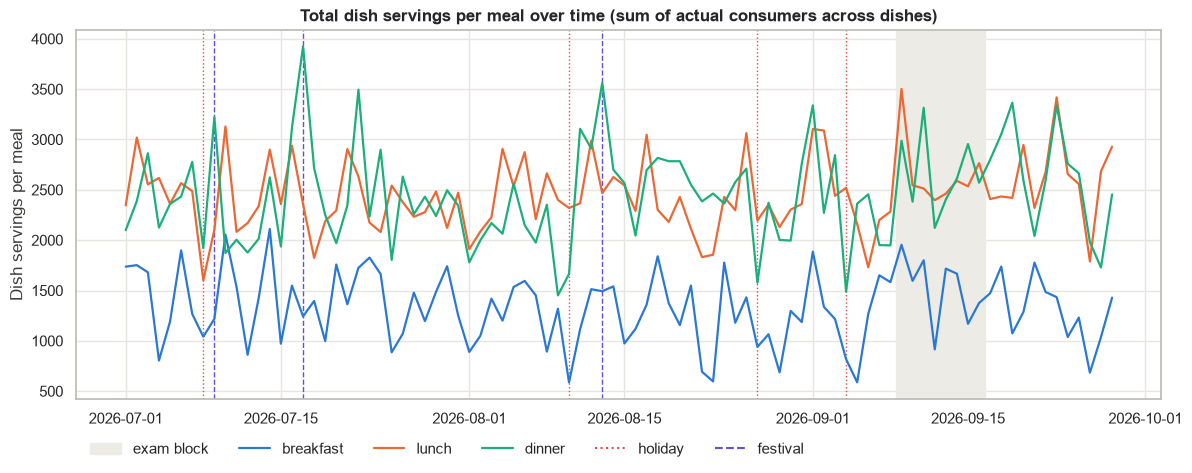

Mean consumers per dish — first 45 days: 412.7 | last 45 days: 428.3


In [27]:
daily = (df.groupby(["date", "meal_type"], observed=True)[[TARGET, "interested_taps"]].sum()
           .reset_index())
fig, ax = plt.subplots(figsize=(14, 4.8))
ex = days.index[days["is_exam_day"]]
ax.axvspan(ex.min() - pd.Timedelta(hours=12), ex.max() + pd.Timedelta(hours=12),
           color="#ecebe6", label="exam block")
for dte in days.index[days["is_holiday"]]:
    ax.axvline(dte, color="#e34948", lw=1, ls=":")
for dte in days.index[days["is_festival"]]:
    ax.axvline(dte, color="#6250d6", lw=1, ls="--")
for meal in MEAL_ORDER:
    s = daily[daily["meal_type"] == meal]
    ax.plot(s["date"], s[TARGET], lw=1.6, color=MEAL_COLORS[meal], label=meal)
ax.plot([], [], color="#e34948", ls=":", label="holiday")
ax.plot([], [], color="#6250d6", ls="--", label="festival")
ax.set(title="Total dish servings per meal over time (sum of actual consumers across dishes)",
       xlabel="", ylabel="Dish servings per meal")
ax.legend(frameon=False, ncol=6, loc="upper left", bbox_to_anchor=(0, -0.08))
save(fig, "time_trend_meals"); plt.show()

first_half = df[df["date"] < df["date"].min() + pd.Timedelta(days=45)][TARGET].mean()
second_half = df[df["date"] >= df["date"].min() + pd.Timedelta(days=45)][TARGET].mean()
print(f"Mean consumers per dish — first 45 days: {first_half:.1f} | last 45 days: {second_half:.1f}")

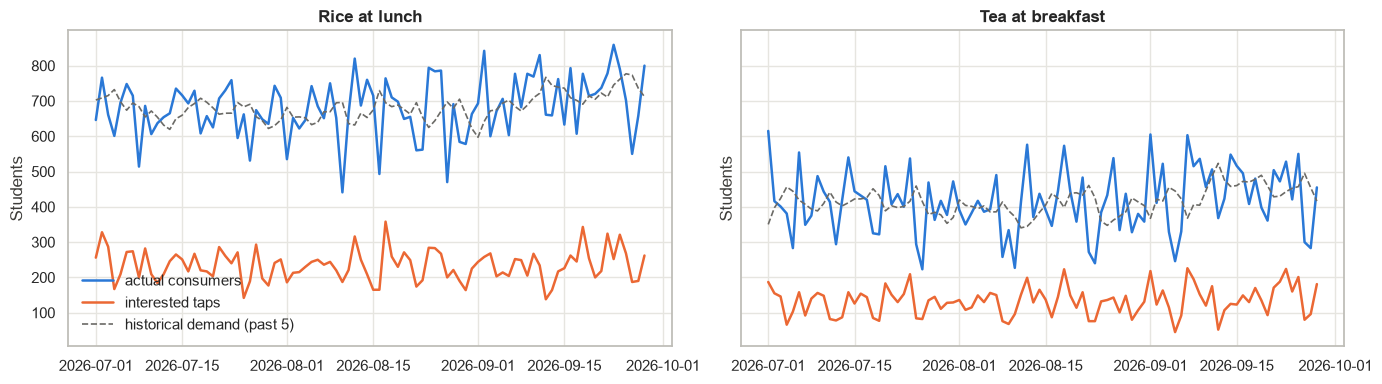

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (dish, meal) in zip(axes, [("Rice", "lunch"), ("Tea", "breakfast")]):
    s = df[(df["dish_name"] == dish) & (df["meal_type"] == meal)]
    ax.plot(s["date"], s[TARGET], lw=1.8, color=SINGLE, label="actual consumers")
    ax.plot(s["date"], s["interested_taps"], lw=1.8, color="#eb6834", label="interested taps")
    ax.plot(s["date"], s["historical_dish_demand"], lw=1.2, color=INK_MUTED, ls="--",
            label="historical demand (past 5)")
    ax.set(title=f"{dish} at {meal}", xlabel="", ylabel="Students")
axes[0].legend(frameon=False, loc="lower left")
fig.tight_layout(); save(fig, "time_trend_dishes"); plt.show()

**Interpretation.** There is **no long-term trend**: mean consumers per dish are 413 in the first 45 days and 428 in the last 45, and the small rise coincides with the exam block. Variation is driven by individual days: dips on holidays (e.g. 2026-07-08, 08-10) and spikes on festival dinners (07-17 and 08-13 reach 3,500–3,900 dish servings). For individual dishes (Rice at lunch, Tea at breakfast), actual consumers sit well above taps throughout, and the history line follows the actuals with a lag, as expected.

## 10. Correlation heatmap

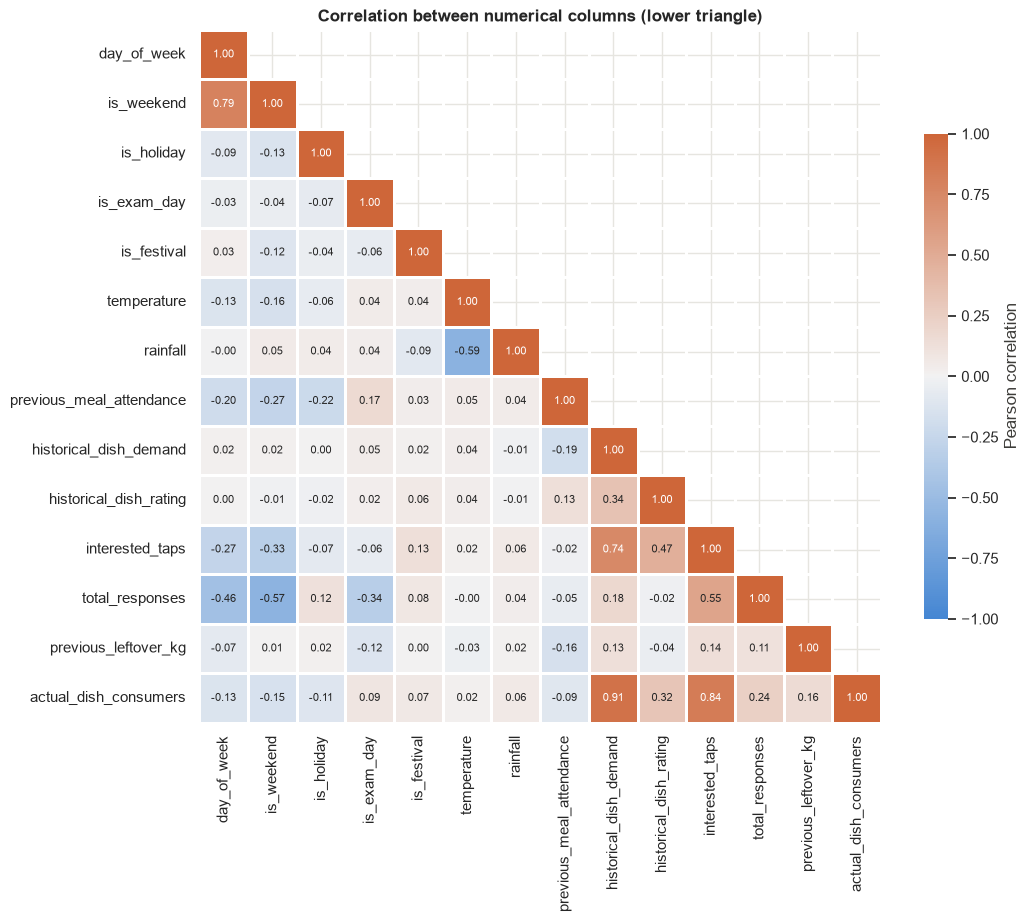

,corr_with_target
historical_dish_demand,0.912
interested_taps,0.836
historical_dish_rating,0.317
total_responses,0.239
previous_leftover_kg,0.162
is_weekend,-0.149
day_of_week,-0.130
is_holiday,-0.113
previous_meal_attendance,-0.094
is_exam_day,0.093


In [29]:
CORR_COLS = ["day_of_week", "is_weekend", "is_holiday", "is_exam_day", "is_festival",
             "temperature", "rainfall", "previous_meal_attendance", "historical_dish_demand",
             "historical_dish_rating", "interested_taps", "total_responses",
             "previous_leftover_kg", TARGET]
# total_students is excluded: it is constant (1000), so its correlation is undefined.
corr = df[CORR_COLS].astype(float).corr()
fig, ax = plt.subplots(figsize=(11, 9))
cmap = sns.diverging_palette(250, 25, s=80, l=55, center="light", as_cmap=True)
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap=cmap, vmin=-1, vmax=1,
            center=0, annot=True, fmt=".2f", annot_kws={"size": 8}, linewidths=1, linecolor="white",
            cbar_kws={"label": "Pearson correlation", "shrink": 0.7}, ax=ax)
ax.set_title("Correlation between numerical columns (lower triangle)")
save(fig, "correlation_heatmap"); plt.show()
display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("corr_with_target"))

**Interpretation.** Only two inputs correlate strongly with the target: `historical_dish_demand` (0.91) and `interested_taps` (0.84). They also correlate with each other (0.74), so they partly carry the same information about dish popularity. `day_of_week` and `is_weekend` overlap (0.79), as do `temperature` and `rainfall` (−0.59), and `total_responses` drops on weekends (−0.57). Calendar flags have small *linear* correlations (|r| < 0.16) even though section 8.3 shows large effects. They are rare events with effects that differ by meal type, which Pearson correlation understates; tree models can still use them. No input exceeds 0.95, which would suggest leakage.

## 11. New dishes & missing historical values

In [30]:
first_seen = (df.groupby(["dish_name", "meal_type"], observed=True)["date"].min()
                .rename("first_date_in_window").reset_index())
first_rows = df.merge(first_seen, on=["dish_name", "meal_type"])
first_rows = first_rows[first_rows["date"] == first_rows["first_date_in_window"]]
print("Dish/meal pairs:", len(first_seen))
print("First in-window serving that still HAS history (served during warm-up):",
      first_rows["historical_dish_demand"].notna().sum())
print("First in-window serving with NO history (genuinely new dish):",
      first_rows["historical_dish_demand"].isna().sum())
display(first_rows[first_rows["historical_dish_demand"].isna()]
        [["date", "meal_type", "dish_name", "dish_category", "interested_taps", TARGET]])

Dish/meal pairs: 40
First in-window serving that still HAS history (served during warm-up): 39
First in-window serving with NO history (genuinely new dish): 1


,date,meal_type,dish_name,dish_category,interested_taps,actual_dish_consumers
74,2026-07-05,dinner,Aloo Matar,main_veg,124,299


In [31]:
nan_hist = df[df[["historical_dish_demand", "historical_dish_rating", "previous_leftover_kg"]].isna().any(axis=1)]
print("Missingness pattern — are the 3 history columns missing on the same rows?")
display(df[["historical_dish_demand", "historical_dish_rating", "previous_leftover_kg"]].isna()
          .value_counts().to_frame("rows"))
ref = df[(df["dish_name"] == "Aloo Matar") & (df["meal_type"] == "dinner")]
print("All servings of Aloo Matar (dinner):")
display(ref[["date", "interested_taps", "historical_dish_demand", "historical_dish_rating",
             "previous_leftover_kg", TARGET]].head(6))

Missingness pattern — are the 3 history columns missing on the same rows?


,,,rows
historical_dish_demand,historical_dish_rating,previous_leftover_kg,
False,False,False,1336
True,True,True,1


All servings of Aloo Matar (dinner):


,date,interested_taps,historical_dish_demand,historical_dish_rating,previous_leftover_kg,actual_dish_consumers
74,2026-07-05,124,NaN,NaN,NaN,299
116,2026-07-08,100,299.0,3.62,3.7,194
130,2026-07-09,151,246.5,3.66,25.4,281
431,2026-07-29,124,258.0,3.34,14.3,270
488,2026-08-02,128,261.0,3.34,13.3,288
532,2026-08-05,119,266.4,3.25,9.4,305


### 11.1 Calendar coverage under a chronological split (preview only — no split is saved)

Phase 4 will split by date. Here we only *count* which special days would land in each part of a
70 / 15 / 15 split, to see whether the training period contains examples of every event.

In [32]:
all_days = np.sort(df["date"].unique())
n_days = len(all_days)
train_end = all_days[round(0.70 * n_days) - 1]
val_end = all_days[round(0.85 * n_days) - 1]
cov = days.copy()
cov["part"] = np.where(cov.index <= train_end, "1 train", np.where(cov.index <= val_end, "2 validation", "3 test"))
print("train <=", pd.Timestamp(train_end).date(), "| validation <=", pd.Timestamp(val_end).date())
display(cov.groupby("part")[["is_weekend", "is_holiday", "is_exam_day", "is_festival"]].sum()
          .join(cov.groupby("part").size().rename("days")))

train <= 2026-09-01 | validation <= 2026-09-14


,is_weekend,is_holiday,is_exam_day,is_festival,days
part,,,,,
1 train,18,3,0,3,63
2 validation,4,1,6,0,13
3 test,4,0,2,0,14


**Interpretation.** Only **one** dish–meal pair (Aloo Matar at dinner, first served 2026-07-05) has no history. The other 39 pairs had already been served during the generator's 21-day warm-up, which is not in the CSV, so their first rows here still have history. All three history columns are missing together on that one row and nowhere else, so this is a **'new dish' case, not random missingness**. From its second serving onward the history columns fill in normally. In production new dishes will be common, so Phase 4 needs an explicit rule for them rather than dropping the row. **Split coverage (section 11.1):** under a chronological 70/15/15 split, **the training period contains zero exam days**. All 8 fall in validation (6) and test (2). Training does contain all 3 festivals and 3 of the 4 holidays, while validation has the remaining holiday. So the model cannot learn the exam effect from the training data, and test results on exam days will reflect that gap.

## 12. Leakage investigation

Leakage = the model sees information at training time that it would **not** have when making a real
prediction before the meal. Three checks:

1. **Availability** — every candidate input must be known before the meal.
2. **No post-meal columns** — the target and current-meal leftovers/ratings/attendance must not be inputs.
3. **History is past-only** — history columns must be computed from earlier meals only.

### 12.1 Availability of each column (from the data dictionary)

In [33]:
rows = []
for line in DICT_PATH.read_text(encoding="utf-8").splitlines():
    m = re.match(r"\|\s*`([^`]+)`\s*\|([^|]*)\|([^|]*)\|([^|]*)\|", line)
    if m:
        rows.append({"column": m[1], "known_before_meal": m[3].strip(), "role": m[4].strip()})
avail = pd.DataFrame(rows).set_index("column")
missing_from_dict = set(df.columns) - set(avail.index)
print("Columns in CSV but not in dictionary:", missing_from_dict or "none")
# date is an ID / split key: the model gets features DERIVED from it (day_of_week...), not the raw date.
avail["usable_as_input"] = (avail["known_before_meal"].str.startswith("yes")
                            & ~avail["role"].isin(["metadata", "id / split key"]))
display(avail)
print("NOT usable as model input:", avail.index[~avail["usable_as_input"]].tolist())

Columns in CSV but not in dictionary: none


,known_before_meal,role,usable_as_input
column,,,
date,yes,id / split key,False
meal_type,yes,feature,True
dish_name,yes,feature / id,True
dish_category,yes,feature,True
day_of_week,yes,feature,True
is_weekend,yes,feature,True
is_holiday,yes,feature,True
is_exam_day,yes,feature,True
is_festival,yes,feature,True


NOT usable as model input: ['date', 'actual_dish_consumers', 'data_source']


### 12.2 Post-meal information must not appear as a current-row input

In [34]:
POST_MEAL_WORDS = ["leftover", "rating", "attendance", "consumers"]
flagged = []
for col in df.columns:
    if any(w in col for w in POST_MEAL_WORDS) and col != TARGET:
        is_past = col.startswith(("previous_", "historical_"))
        flagged.append({"column": col, "named_as_past_value": is_past})
display(pd.DataFrame(flagged))
assert all(f["named_as_past_value"] for f in flagged), "a post-meal-sounding column is not a past value"
print("Target column is", TARGET, "-> it will be separated as y and never included in X.")

corr_t = df[CORR_COLS].astype(float).corr()[TARGET].drop(TARGET).abs()
print("Highest |correlation| of any input with the target:", corr_t.idxmax(), round(corr_t.max(), 3))
print("Any input with |corr| > 0.95 (suspiciously perfect)?", bool((corr_t > 0.95).any()))

,column,named_as_past_value
0,previous_meal_attendance,True
1,historical_dish_rating,True
2,previous_leftover_kg,True


Target column is actual_dish_consumers -> it will be separated as y and never included in X.
Highest |correlation| of any input with the target: historical_dish_demand 0.912
Any input with |corr| > 0.95 (suspiciously perfect)? False


### 12.3 History columns use past meals only

* `historical_dish_demand` can be **recomputed** from the CSV: mean of the previous 5 actuals of the same
  dish at the same meal type. If the generator had (wrongly) included the current row, a different formula
  would match instead.
* `previous_meal_attendance` and `previous_leftover_kg` come from hidden values that are not in the CSV
  (meal headcount, leftover), so they cannot be recomputed. Instead we test **timing**: a correctly
  lagged column should line up better with the *previous* meal/serving than with the *current* one.

In [35]:
d = df.copy()
d["meal_order"] = d["meal_type"].cat.codes
d = d.sort_values(["date", "meal_order", "dish_name"])
g = d.groupby(["dish_name", "meal_type"], observed=True)[TARGET]
d["n_prior_in_window"] = d.groupby(["dish_name", "meal_type"], observed=True).cumcount()
d["recalc_past_only"] = g.transform(lambda s: s.shift(1).rolling(5).mean()).round(1)
d["recalc_incl_current"] = g.transform(lambda s: s.rolling(5).mean()).round(1)
chk = d[d["n_prior_in_window"] >= 5]   # earlier rows depend on warm-up days not stored in the CSV
match_past = ((chk["recalc_past_only"] - chk["historical_dish_demand"]).abs() < 0.051).sum()
match_curr = ((chk["recalc_incl_current"] - chk["historical_dish_demand"]).abs() < 0.051).sum()
print(f"Rows checkable: {len(chk)}")
print(f"Match with PAST-ONLY formula        : {match_past}")
print(f"Match with formula INCLUDING current: {match_curr}")

Rows checkable: 1137
Match with PAST-ONLY formula        : 1137
Match with formula INCLUDING current: 6


In [36]:
# previous_meal_attendance: compare with the total dish servings of the current vs the previous meal.
meals = (d.groupby(["date", "meal_order"])
           .agg(prev_att=("previous_meal_attendance", "first"), servings=(TARGET, "sum"))
           .reset_index().sort_values(["date", "meal_order"]))
meals["servings_prev_meal"] = meals["servings"].shift(1)
print("corr(previous_meal_attendance, servings of CURRENT meal) :",
      round(meals["prev_att"].corr(meals["servings"]), 3))
print("corr(previous_meal_attendance, servings of PREVIOUS meal):",
      round(meals["prev_att"].corr(meals["servings_prev_meal"]), 3))

# previous_leftover_kg: leftover = prepared - eaten, so it should relate (negatively) to the
# PREVIOUS serving's actual. Compared WITHIN each dish (values minus the dish's own mean), because
# pooled across dishes, big dishes have both big leftovers and big demand, which hides the link.
d["actual_prev_serving"] = g.shift(1)
lv = d.dropna(subset=["previous_leftover_kg", "actual_prev_serving"]).copy()
for c in ["previous_leftover_kg", "actual_prev_serving", TARGET]:
    lv[c + "_within"] = lv[c] - lv.groupby(["dish_name", "meal_type"], observed=True)[c].transform("mean")
print("\nPooled across dishes (confounded by dish size):")
print("  corr(previous_leftover_kg, actual CURRENT serving) :", round(lv["previous_leftover_kg"].corr(lv[TARGET]), 3))
print("  corr(previous_leftover_kg, actual PREVIOUS serving):", round(lv["previous_leftover_kg"].corr(lv["actual_prev_serving"]), 3))
print("Within each dish:")
print("  corr(previous_leftover_kg, actual CURRENT serving) :",
      round(lv["previous_leftover_kg_within"].corr(lv[TARGET + "_within"]), 3))
print("  corr(previous_leftover_kg, actual PREVIOUS serving):",
      round(lv["previous_leftover_kg_within"].corr(lv["actual_prev_serving_within"]), 3))

corr(previous_meal_attendance, servings of CURRENT meal) : -0.116
corr(previous_meal_attendance, servings of PREVIOUS meal): 0.861

Pooled across dishes (confounded by dish size):
  corr(previous_leftover_kg, actual CURRENT serving) : 0.166
  corr(previous_leftover_kg, actual PREVIOUS serving): -0.093
Within each dish:
  corr(previous_leftover_kg, actual CURRENT serving) : -0.026
  corr(previous_leftover_kg, actual PREVIOUS serving): -0.781


**Interpretation.** **All leakage checks pass.** (1) *Availability:* every input column is marked 'known before the meal' in the data dictionary. Only the target (`actual_dish_consumers`) and `data_source` are excluded; `date` is an ID and split key whose derived parts (day of week, flags) are already columns. (2) *No post-meal inputs:* every column mentioning leftover, rating or attendance is a `previous_` or `historical_` value, and no input correlates above 0.95 with the target. (3) *Past-only history:* `historical_dish_demand` recomputed with a past-only formula matches **all 1,137 checkable rows**, against only 6 for a formula that wrongly includes the current row. `previous_meal_attendance` correlates 0.86 with the *previous* meal's total servings but −0.12 with the *current* meal's. Within each dish, `previous_leftover_kg` correlates strongly and negatively (about −0.78) with the *previous* serving's consumers and about 0 with the *current* one. Both columns therefore line up with the meal before, not the current one. **Limitations:** `historical_dish_rating` cannot be recomputed because per-meal ratings are not stored; its correctness rests on the generator code (`shift(1)` before averaging). About 200 early rows depend on warm-up days and also cannot be rechecked.

## 13. Summary

* **Data quality is good:** no duplicates, no rule violations, and one structurally missing row (a new dish).
* **The target is driven by** meal type, the dish, its recent history (r = 0.91) and app taps (r = 0.84), adjusted by calendar events (holiday, weekend, exam, festival) and rain.
* **Taps ≠ consumption:** consumers are about 2.6× taps, and the ratio depends on the dish category, so the model must learn the conversion.
* **No leakage found.** History is past-only (1,137/1,137 recomputed rows match), and post-meal values only appear as lagged features.
* **Watch for in Phase 4:** `total_students` is constant (no information); one new-dish row needs a rule; **the chronological training period has no exam days**; rare dishes have only 9–13 servings.
* **Everything above is SYNTHETIC.** These patterns were designed into the generator and are not evidence about real mess behaviour.

Full write-up: [`docs/eda_report.md`](../docs/eda_report.md).